# 03 · Nasdaq ITCH: ricostruire il book ordine per ordine

**TotalView-ITCH** è il flusso con cui il Nasdaq comunica ogni singolo evento del book: ogni ordine inserito, eseguito, cancellato o modificato, con il suo identificativo. È un dato **L3** (*market by order*): permette di sapere quanti ordini ci sono davanti al proprio a ogni prezzo, cioè la **posizione in coda**.

| Messaggio ITCH | Significato |
|---|---|
| `A`, `F` | nuovo ordine nel book |
| `E`, `C` | esecuzione (totale o parziale) di un ordine |
| `X` | cancellazione parziale |
| `D` | cancellazione totale |
| `U` | sostituzione (nuovo prezzo o quantità, perde la priorità) |

Si usano i sette file giornalieri pubblici completi (3,5-5,6 GB compressi ciascuno) per AAPL, MSFT e INTC, sessione regolare **09:30-16:00**. I messaggi prima delle 09:30 servono solo a ricostruire il book di apertura.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
ingest = pd.DataFrame(R.load_json(ROOT, "ingest/itch")["sessions"])
quality = R.load(ROOT, "quality").query("dataset == 'itch'")
anomaly_cols = ["ts_decreasing", "nonpositive_size", "unknown_order", "duplicate_add", "overfill", "crossed"]
R.show_box("In breve", [
    f"{it(ingest.messages.sum() / 1e9, 2)} miliardi di messaggi letti in 7 giornate, a circa {it(ingest.messages_per_second.mean() / 1e6, 1)} milioni al secondo per processo.",
    f"{it(quality.records.sum() / 1e6, 1)} milioni di aggiornamenti del book per i tre titoli nelle sessioni regolari.",
    f"Anomalie nel book ricostruito: {int(quality[anomaly_cols].sum().sum())}.",
])

> **In breve**
>
> - 2,35 miliardi di messaggi letti in 7 giornate, a circa 1,3 milioni al secondo per processo.
> - 28,1 milioni di aggiornamenti del book per i tre titoli nelle sessioni regolari.
> - Anomalie nel book ricostruito: 0.

## 1. Lettura dei file

Il parser decomprime ogni file a blocchi, legge di ogni messaggio solo il tipo e il codice del titolo e decodifica per intero soltanto i messaggi dei tre titoli. Si ferma alla chiusura delle 16:00. Gli eventi sono salvati in Parquet, un file per titolo e giornata.

In [2]:
table = pd.DataFrame({
    "giornata": ingest.session,
    "messaggi letti (milioni)": (ingest.messages / 1e6).round(0).astype(int),
    "eventi AAPL": ingest.rows.map(lambda r: it(r["AAPL"])),
    "eventi MSFT": ingest.rows.map(lambda r: it(r["MSFT"])),
    "eventi INTC": ingest.rows.map(lambda r: it(r["INTC"])),
    "tempo (s)": ingest.seconds.round(0).astype(int),
}).set_index("giornata")
display(table)

,messaggi letti (milioni),eventi AAPL,eventi MSFT,eventi INTC,tempo (s)
giornata,,,,,
2019-01-30,367,1.653.277,1.600.176,1.161.669,276
2019-03-27,420,1.966.458,2.113.745,1.404.955,312
2019-07-30,280,1.231.999,1.198.918,811.546,210
2019-08-30,309,1.190.065,1.552.841,970.055,234
2019-10-30,291,734.884,1.210.066,919.429,219
2019-12-30,267,1.485.761,1.193.969,742.360,203
2020-01-30,419,1.960.587,1.798.035,1.587.095,313


## 2. Il book ricostruito è coerente?

Il flusso di ogni sessione viene rigiocato nel book e si contano le situazioni impossibili: orari che tornano indietro, quantità negative, esecuzioni o cancellazioni di ordini mai inseriti, ordini inseriti due volte, esecuzioni più grandi dell'ordine, miglior prezzo in acquisto sopra quello in vendita (*book incrociato*). Devono essere tutte zero.

In [3]:
labels = {"ts_decreasing": "orari all'indietro", "nonpositive_size": "quantità non positive",
          "unknown_order": "ordini sconosciuti", "duplicate_add": "ordini duplicati",
          "overfill": "esecuzioni oltre l'ordine", "crossed": "book incrociato"}
checks = quality.groupby("session")[["records", *anomaly_cols]].sum().rename(columns={"records": "aggiornamenti", **labels})
display(checks.style.format("{:,.0f}"))
assert quality[anomaly_cols].sum().sum() == 0

,aggiornamenti,orari all'indietro,quantità non positive,ordini sconosciuti,ordini duplicati,esecuzioni oltre l'ordine,book incrociato
session,,,,,,,
2019-01-30,"4,305,619",0,0,0,0,0,0
2019-03-27,"5,467,978",0,0,0,0,0,0
2019-07-30,"3,186,407",0,0,0,0,0,0
2019-08-30,"3,622,602",0,0,0,0,0,0
2019-10-30,"2,853,023",0,0,0,0,0,0
2019-12-30,"3,405,910",0,0,0,0,0,0
2020-01-30,"5,305,126",0,0,0,0,0,0


## 3. Una giornata di AAPL

Prezzi migliori e spread ricostruiti dal solo flusso dei messaggi.

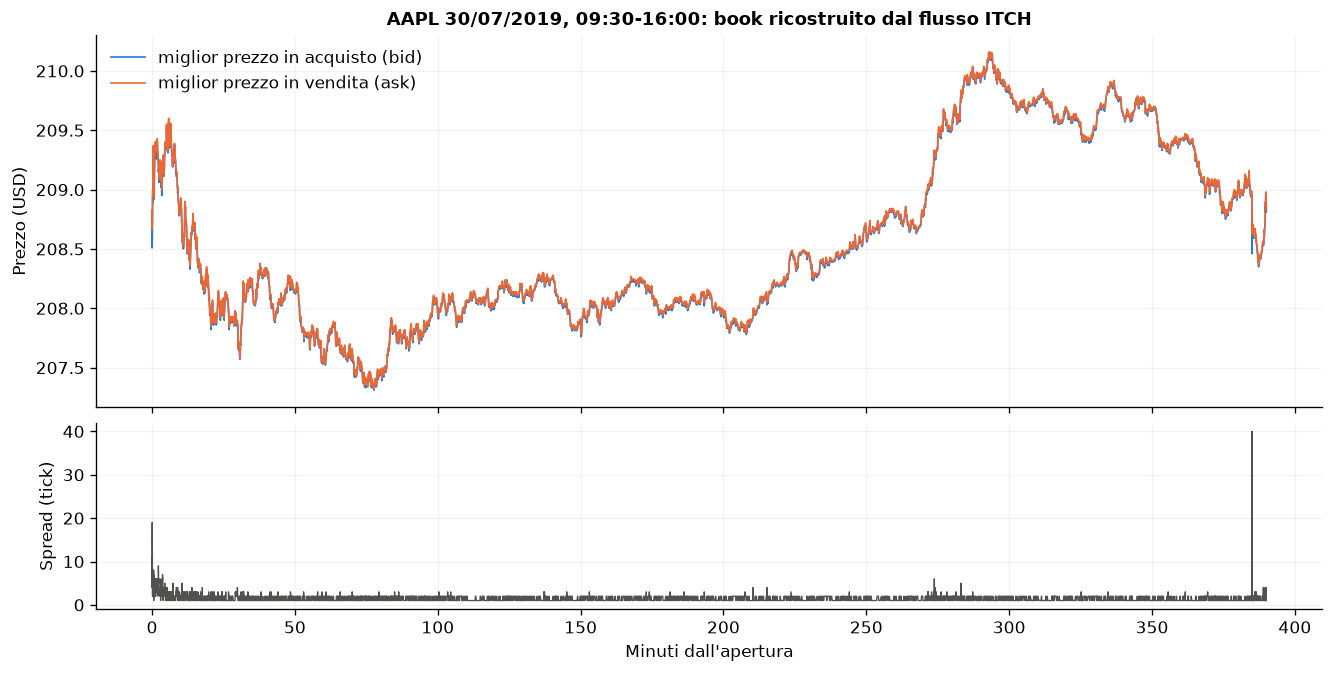

**Come leggerlo.** Lo spread è di un solo tick (1 centesimo) nel 56% degli aggiornamenti; al miglior prezzo ci sono in mediana 230 azioni in acquisto e 235 in vendita. Un ordine di 100 azioni inserito al miglior prezzo finisce quindi in fondo a una coda di alcune centinaia di azioni: è questa coda che le regole L2 ignorano.

In [4]:
from market_making_tesi.pipeline import DATASETS, events, l2_view, session_list
spec = DATASETS["itch"]
path = next(p for s, sym, p in session_list(ROOT, spec) if s == "2019-07-30" and sym == "AAPL")
view = pd.DataFrame([(s.timestamp, s.best_bid, s.best_ask, s.bid_sizes[0], s.ask_sizes[0])
                     for s in l2_view(events(spec, path, "AAPL"))], columns=["ts", "bid", "ask", "bid_sz", "ask_sz"])
v = view.iloc[::max(1, len(view) // 4000)]
x = (v.ts - v.ts.iloc[0]) / 6e10
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(x, v.bid, color=R.COLORS["touch"], linewidth=1, label="miglior prezzo in acquisto (bid)")
axes[0].plot(x, v.ask, color=R.COLORS["price-through"], linewidth=1, label="miglior prezzo in vendita (ask)")
axes[0].set(title="AAPL 30/07/2019, 09:30-16:00: book ricostruito dal flusso ITCH", ylabel="Prezzo (USD)")
axes[0].legend(frameon=False)
axes[1].plot(x, ((v.ask - v.bid) / 0.01).round(), color=R.INK, linewidth=0.8)
axes[1].set(xlabel="Minuti dall'apertura", ylabel="Spread (tick)")
fig.savefig(FIGURES / "itch_book_aapl.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown(
    f"**Come leggerlo.** Lo spread è di un solo tick (1 centesimo) {R.nel(((view.ask - view.bid) < 0.0101).mean(), 0)} "
    f"degli aggiornamenti; al miglior prezzo ci sono in mediana {it(view.bid_sz.median())} azioni in acquisto e "
    f"{it(view.ask_sz.median())} in vendita. Un ordine di 100 azioni inserito al miglior prezzo finisce quindi in fondo "
    "a una coda di alcune centinaia di azioni: è questa coda che le regole L2 ignorano."))

## 4. Dallo stesso flusso, anche la vista L2

Per il confronto del notebook 04, la vista L2 usata da `touch`, `price-through` e `cross` viene ricostruita **dallo stesso flusso ITCH**, aggiornamento per aggiornamento. Così le quattro regole vedono esattamente lo stesso mercato e differiscono solo nel modo di decidere le esecuzioni.